# Предварительная проверка цены сделки с жилой недвижимостью: модель для правовой экспертизы (Самара)

**Автор:** Павлов Юрий Николаевич  
**Инструменты:** Python (pandas, NumPy, scikit-learn, matplotlib, seaborn)

> **Статус данных.** В репозитории используются **смоделированные данные**: реальные сделки закрыты коммерческой и иной охраняемой законом тайной. Допущения генератора заданы в явном виде в разделе 2. Ноутбук работает без изменения кода и на **обезличенной выгрузке сделок** (файл `data/deals.csv`, схема описана ниже): тогда модель, графики и выводы пересчитываются автоматически.

---

## Практическая задача

При правовой экспертизе сделки купли-продажи необходимо оценить, насколько цена в договоре согласуется с рынком. Существенное отклонение не доказывает нарушения, но является основанием для дополнительной проверки: оценки банка при ипотеке, налоговых последствий, риска оспаривания сделки.

**Что делает ноутбук:**
1. проверяет качество данных;
2. строит интерпретируемую модель цены (логарифмическая регрессия: коэффициенты читаются как процентные эффекты);
3. проверяет модель на отложенной выборке и перекрёстной проверкой;
4. формирует **инструмент предварительной проверки**: ожидаемая цена, допустимый коридор и заключение «в пределах коридора / требуется проверка».

> **Оговорка.** Предварительная проверка не является оценкой рыночной стоимости. Оценку стоимости в рамках оценочной деятельности проводит оценщик (Федеральный закон № 135-ФЗ «Об оценочной деятельности в Российской Федерации»). Модель помогает юристу определить, где такая оценка или дополнительные документы необходимы.

## 1. Подготовка

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams['figure.figsize'] = (11, 5)
sns.set_style('whitegrid')

ANALYSIS_YEAR = 2026                  # фиксированный год: результаты воспроизводимы
SEED = 42
DATA_PATH = 'data/deals.csv'          # сюда кладётся обезличенная выгрузка сделок
SAMPLE_PATH = 'data/sample_deals_synthetic.csv'
os.makedirs('data', exist_ok=True)

## 2. Схема данных и допущения

**Схема выгрузки** (одна строка - одна сделка; обезличенный файл должен содержать эти столбцы):

| Столбец | Описание |
|---|---|
| `район` | один из девяти районов Самары |
| `комнат` | число комнат |
| `площадь_м2` | общая площадь, м² |
| `этаж`, `этажей_в_доме` | этаж квартиры и этажность дома |
| `год_постройки` | год постройки дома |
| `ремонт` | без ремонта / косметический / евроремонт |
| `цена_руб` | цена по договору, руб. |

Перед загрузкой реальных данных исключаются адреса, ФИО и иные сведения, позволяющие идентифицировать стороны.

**Допущения генератора** (используются только для смоделированных данных). Уровень цен и коэффициенты - **ориентировочные допущения, а не рыночная статистика**; коэффициенты центральных районов (Ленинский, Самарский) являются оценочными и подлежат уточнению по актуальным данным на дату анализа.

In [2]:
ASSUMPTIONS = {
    'base_price_m2': 126_000,   # ориентировочный уровень цены за м² базового района (подлежит актуализации)
    'district_coef': {'Ленинский': 1.50, 'Самарский': 1.40, 'Октябрьский': 1.15, 'Советский': 1.08,
                      'Кировский': 1.00, 'Промышленный': 1.00, 'Железнодорожный': 0.96,
                      'Красноглинский': 0.98, 'Куйбышевский': 0.93},
    'renov_coef': {'без ремонта': 0.88, 'косметический': 1.00, 'евроремонт': 1.16},
    'age_decay_per_year': 0.003,   # снижение цены за каждый год возраста дома
    'first_floor': 0.94,
    'last_floor': 0.96,
    'noise': (0.93, 1.07),         # рыночный разброс
}
DISTRICTS = ['Ленинский', 'Самарский', 'Октябрьский', 'Советский', 'Кировский',
             'Промышленный', 'Железнодорожный', 'Красноглинский', 'Куйбышевский']
RENOV = ['без ремонта', 'косметический', 'евроремонт']
BASE_DISTRICT, BASE_RENOV = 'Кировский', 'косметический'
REQUIRED = ['район', 'комнат', 'площадь_м2', 'этаж', 'этажей_в_доме', 'год_постройки', 'ремонт', 'цена_руб']
pd.DataFrame({'район': ASSUMPTIONS['district_coef']}).T

,Ленинский,Самарский,Октябрьский,Советский,Кировский,Промышленный,Железнодорожный,Красноглинский,Куйбышевский
район,1.50,1.40,1.15,1.08,1.00,1.00,0.96,0.98,0.93


## 3. Загрузка данных
Если в папке `data/` есть файл `deals.csv`, анализируется он; иначе генерируется смоделированная выборка из 500 сделок по вторичному рынку.

In [3]:
def generate_deals(n=500, seed=SEED, a=ASSUMPTIONS):
    rng = np.random.default_rng(seed)
    district = rng.choice(DISTRICTS, n, p=[0.08, 0.07, 0.13, 0.14, 0.22, 0.14, 0.09, 0.06, 0.07])
    rooms = rng.choice([1, 2, 3, 4], n, p=[0.35, 0.38, 0.20, 0.07])
    area = rooms * rng.uniform(16, 22, n) + rng.uniform(5, 15, n)
    floor = rng.integers(1, 17, n)
    floors_total = np.clip(floor + rng.integers(0, 9, n), 1, 25)
    hist_years = [1960, 1970, 1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015]
    hist_p = [0.04, 0.06, 0.07, 0.08, 0.08, 0.07, 0.06, 0.07, 0.08, 0.09, 0.09]
    new_years = [2018, 2020, 2022, 2024, ANALYSIS_YEAR]
    year_built = rng.choice(hist_years + new_years, n, p=hist_p + [0.21 / len(new_years)] * len(new_years))
    renovation = rng.choice(RENOV, n, p=[0.30, 0.45, 0.25])
    age = ANALYSIS_YEAR - year_built
    price = (area * a['base_price_m2']
             * np.array([a['district_coef'][d] for d in district])
             * np.array([a['renov_coef'][r] for r in renovation])
             * (1 - a['age_decay_per_year'] * age)
             * np.where(floor == 1, a['first_floor'], 1.0)
             * np.where(floor == floors_total, a['last_floor'], 1.0)
             * rng.uniform(*a['noise'], n))
    return pd.DataFrame({'район': district, 'комнат': rooms, 'площадь_м2': area.round(1), 'этаж': floor,
                         'этажей_в_доме': floors_total, 'год_постройки': year_built,
                         'ремонт': renovation, 'цена_руб': price.round(-3).astype(int)})

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    missing = [c for c in REQUIRED if c not in df.columns]
    assert not missing, f'В файле отсутствуют столбцы: {missing}'
    assert set(df['район']) <= set(DISTRICTS), 'В данных есть районы вне списка DISTRICTS'
    assert set(df['ремонт']) <= set(RENOV), 'В данных есть значения ремонта вне списка RENOV'
    IS_SYNTHETIC = False
else:
    df = generate_deals()
    df.to_csv(SAMPLE_PATH, index=False)
    IS_SYNTHETIC = True

DATA_LABEL = 'СМОДЕЛИРОВАННЫЕ ДАННЫЕ' if IS_SYNTHETIC else 'ОБЕЗЛИЧЕННАЯ ВЫГРУЗКА'
print(f'Источник данных: {DATA_LABEL}')
print(f'Сделок в выборке: {len(df)}')
df.head()

Источник данных: СМОДЕЛИРОВАННЫЕ ДАННЫЕ
Сделок в выборке: 500


,район,комнат,площадь_м2,этаж,этажей_в_доме,год_постройки,ремонт,цена_руб
0,Промышленный,3,60.80,6,12,1960,евроремонт,7045000
1,Кировский,3,70.90,14,18,2010,косметический,8583000
2,Железнодорожный,3,59.00,1,9,2024,без ремонта,5461000
3,Промышленный,2,43.10,8,14,2018,косметический,5405000
4,Самарский,2,52.70,13,13,1985,без ремонта,7099000


## 4. Проверка качества данных
Проверяются пропуски, дубликаты, логические ошибки и выбросы. Ошибки данных должны быть исправлены до построения модели.

In [4]:
df['цена_за_м2'] = (df['цена_руб'] / df['площадь_м2']).round(0)
q1, q3 = df['цена_за_м2'].quantile([0.25, 0.75])
iqr = q3 - q1
checks = {
    'пропуски (всего ячеек)': int(df[REQUIRED].isna().sum().sum()),
    'полные дубликаты строк': int(df.duplicated().sum()),
    'этаж больше этажности дома': int((df['этаж'] > df['этажей_в_доме']).sum()),
    'год постройки позже года анализа': int((df['год_постройки'] > ANALYSIS_YEAR).sum()),
    'площадь вне диапазона 15-250 м²': int((~df['площадь_м2'].between(15, 250)).sum()),
    'цена за м² - выбросы по правилу 1,5 IQR': int(((df['цена_за_м2'] < q1 - 1.5 * iqr) | (df['цена_за_м2'] > q3 + 1.5 * iqr)).sum()),
}
pd.Series(checks, name='количество').to_frame()

,количество
пропуски (всего ячеек),0
полные дубликаты строк,0
этаж больше этажности дома,0
год постройки позже года анализа,0
площадь вне диапазона 15-250 м²,0
"цена за м² - выбросы по правилу 1,5 IQR",21


## 5. Разведочный анализ

Средняя цена сделки:      6,055,158 руб.
Медианная цена сделки:    5,540,000 руб.
Медиана цены за м²:         120,271 руб.
Диапазон цен:          2,079,000 - 20,263,000 руб.


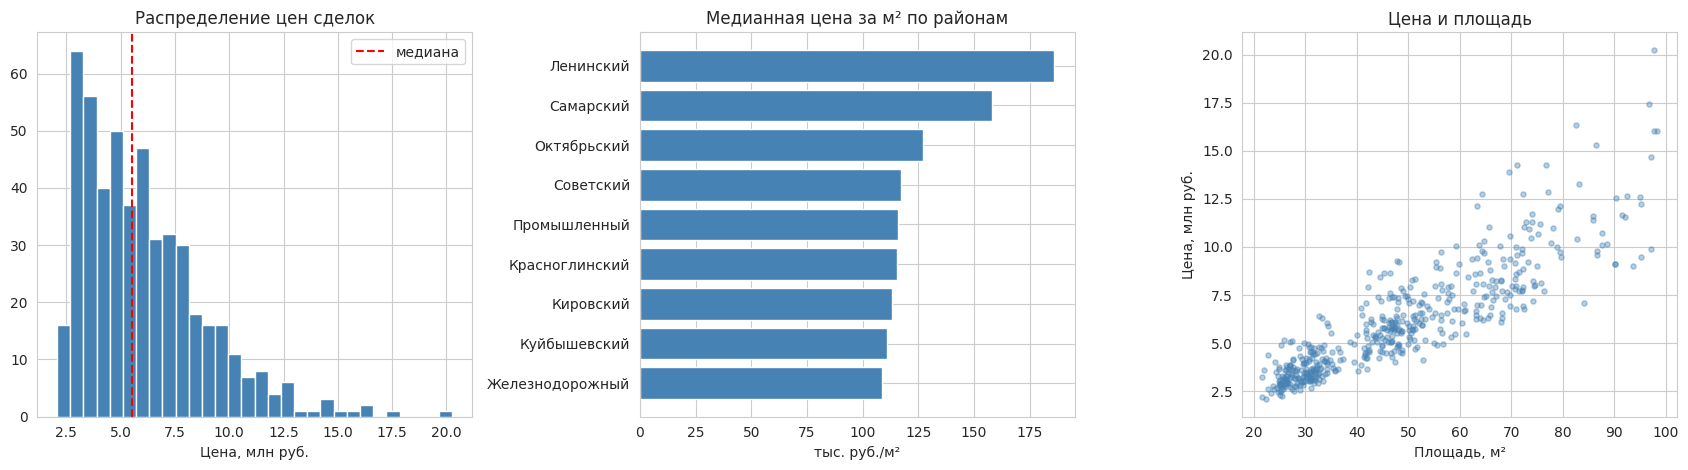

In [5]:
print(f"Средняя цена сделки:   {df['цена_руб'].mean():>12,.0f} руб.")
print(f"Медианная цена сделки: {df['цена_руб'].median():>12,.0f} руб.")
print(f"Медиана цены за м²:    {df['цена_за_м2'].median():>12,.0f} руб.")
print(f"Диапазон цен:          {df['цена_руб'].min():,} - {df['цена_руб'].max():,} руб.")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].hist(df['цена_руб'] / 1e6, bins=30, color='steelblue', edgecolor='white')
axes[0].axvline(df['цена_руб'].median() / 1e6, color='red', linestyle='--', label='медиана')
axes[0].set_title('Распределение цен сделок'); axes[0].set_xlabel('Цена, млн руб.'); axes[0].legend()

dist = df.groupby('район')['цена_за_м2'].median().sort_values(ascending=False) / 1000
axes[1].barh(dist.index[::-1], dist.values[::-1], color='steelblue')
axes[1].set_title('Медианная цена за м² по районам'); axes[1].set_xlabel('тыс. руб./м²')

axes[2].scatter(df['площадь_м2'], df['цена_руб'] / 1e6, s=14, alpha=0.4, color='steelblue')
axes[2].set_title('Цена и площадь'); axes[2].set_xlabel('Площадь, м²'); axes[2].set_ylabel('Цена, млн руб.')
plt.tight_layout(); plt.show()

## 6. Модель
Используется регрессия логарифма цены. Базовые категории: район - Кировский, ремонт - косметический. Эффект признака в процентах: `exp(коэффициент) - 1`. Площадь входит в логарифмической форме, её коэффициент - эластичность цены по площади.

In [6]:
def build_features(d):
    X = pd.DataFrame({'log_площадь': np.log(d['площадь_м2'].astype(float)),
                      'возраст_дома': ANALYSIS_YEAR - d['год_постройки'],
                      'первый_этаж': (d['этаж'] == 1).astype(int),
                      'последний_этаж': (d['этаж'] == d['этажей_в_доме']).astype(int)})
    for r in DISTRICTS:
        if r != BASE_DISTRICT:
            X['район_' + r] = (d['район'] == r).astype(int)
    for r in RENOV:
        if r != BASE_RENOV:
            X['ремонт_' + r] = (d['ремонт'] == r).astype(int)
    return X

X = build_features(df)
y = np.log(df['цена_руб'])
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
model = LinearRegression().fit(X_tr, y_tr)

pred_te = np.exp(model.predict(X_te))
true_te = np.exp(y_te)
r2_log_cv = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=SEED), scoring='r2')
sigma = float(np.std(y_tr - model.predict(X_tr), ddof=X_tr.shape[1] + 1))
metrics = {
    'R² на отложенной выборке (цена)': r2_score(true_te, pred_te),
    'R² перекрёстной проверки, 5 блоков (логарифм цены), среднее': r2_log_cv.mean(),
    'MAE на отложенной выборке, руб.': mean_absolute_error(true_te, pred_te),
    'MAPE на отложенной выборке, %': float(np.mean(np.abs(pred_te / true_te - 1)) * 100),
    'σ остатков (логарифм цены)': sigma,
}
pd.Series(metrics, name='значение').to_frame()

,значение
R² на отложенной выборке (цена),0.99
"R² перекрёстной проверки, 5 блоков (логарифм цены), среднее",0.99
"MAE на отложенной выборке, руб.","229,583.35"
"MAPE на отложенной выборке, %",3.69
σ остатков (логарифм цены),0.04


### Проверка интерпретации коэффициентов
Для смоделированных данных истинные параметры известны, поэтому можно проверить, что методика их восстанавливает. Это проверка **корректности расчёта**, а не рыночное открытие: на реальных данных столбец «заложено» не заполняется.

In [7]:
coef = pd.Series(model.coef_, index=X.columns)
effect = (np.exp(coef) - 1) * 100
rows = []
for name in X.columns:
    if name == 'log_площадь':
        rows.append(('эластичность цены по площади', coef[name], 1.0 if IS_SYNTHETIC else np.nan))
    elif name == 'возраст_дома':
        rows.append(('возраст дома, % за год', effect[name], -0.3 if IS_SYNTHETIC else np.nan))
    else:
        true = np.nan
        if IS_SYNTHETIC:
            a = ASSUMPTIONS
            if name == 'первый_этаж': true = (a['first_floor'] - 1) * 100
            elif name == 'последний_этаж': true = (a['last_floor'] - 1) * 100
            elif name.startswith('район_'): true = (a['district_coef'][name[6:]] - 1) * 100
            elif name.startswith('ремонт_'): true = (a['renov_coef'][name[7:]] - 1) * 100
        rows.append((name.replace('_', ' ', 1) + ', %', effect[name], true))
recovery = pd.DataFrame(rows, columns=['фактор', 'оценка модели', 'заложено' if IS_SYNTHETIC else 'справочно']).set_index('фактор')
if not IS_SYNTHETIC:
    recovery = recovery[['оценка модели']]
recovery.round(1)

,оценка модели,заложено
фактор,,
эластичность цены по площади,1.00,1.00
"возраст дома, % за год",-0.30,-0.30
"первый этаж, %",-4.70,-6.00
"последний этаж, %",-4.60,-4.00
"район Ленинский, %",53.10,50.00
"район Самарский, %",41.70,40.00
"район Октябрьский, %",16.50,15.00
"район Советский, %",8.50,8.00
"район Промышленный, %",0.30,0.00


## 7. Диагностика модели

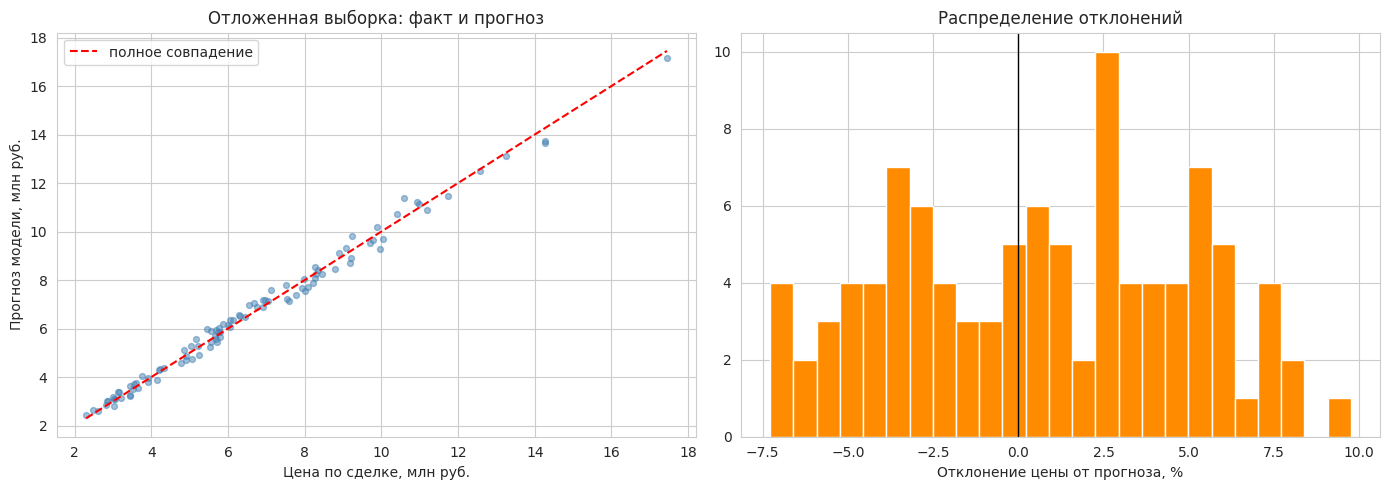

In [8]:
resid_pct = (pred_te / true_te - 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(true_te / 1e6, pred_te / 1e6, s=18, alpha=0.5, color='steelblue')
lim = [min(true_te.min(), pred_te.min()) / 1e6, max(true_te.max(), pred_te.max()) / 1e6]
axes[0].plot(lim, lim, 'r--', label='полное совпадение')
axes[0].set_xlabel('Цена по сделке, млн руб.'); axes[0].set_ylabel('Прогноз модели, млн руб.')
axes[0].set_title('Отложенная выборка: факт и прогноз'); axes[0].legend()
axes[1].hist(resid_pct, bins=25, color='darkorange', edgecolor='white')
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_xlabel('Отклонение цены от прогноза, %'); axes[1].set_title('Распределение отклонений')
plt.tight_layout(); plt.show()

## 8. Инструмент предварительной проверки сделки
Коридор допустимых цен: прогноз × exp(±1,96·σ). Если цена по договору выходит за коридор, сделка направляется на дополнительную проверку. Корректность коридора проверяется на отложенной выборке: в коридор должно попадать около 95% сделок.

In [9]:
def check_deal(район, комнат, площадь_м2, этаж, этажей_в_доме, год_постройки, ремонт, цена_руб, z=1.96):
    d = pd.DataFrame([dict(район=район, комнат=комнат, площадь_м2=площадь_м2, этаж=этаж,
                           этажей_в_доме=этажей_в_доме, год_постройки=год_постройки, ремонт=ремонт)])
    pred = float(np.exp(model.predict(build_features(d))[0]))
    lo, hi = pred * np.exp(-z * sigma), pred * np.exp(z * sigma)
    if цена_руб < lo:
        verdict = 'ниже коридора: требуется проверка (занижение цены)'
    elif цена_руб > hi:
        verdict = 'выше коридора: требуется проверка (завышение цены)'
    else:
        verdict = 'в пределах коридора'
    return dict(ожидаемая_цена=round(pred, -3), нижняя_граница=round(lo, -3), верхняя_граница=round(hi, -3),
                цена_по_договору=цена_руб, отклонение_pct=round((цена_руб / pred - 1) * 100, 1), заключение=verdict)

inside = ((true_te >= pred_te * np.exp(-1.96 * sigma)) & (true_te <= pred_te * np.exp(1.96 * sigma))).mean() * 100
print(f'Доля сделок отложенной выборки внутри коридора: {inside:.1f}% (при нормально распределённых остатках ожидается около 95%)')

base = dict(район='Кировский', комнат=2, площадь_м2=52.0, этаж=5, этажей_в_доме=9, год_постройки=1990, ремонт='косметический')
expected = check_deal(**base, цена_руб=1)['ожидаемая_цена']
examples = pd.DataFrame([check_deal(**base, цена_руб=round(expected * k, -3)) for k in (1.03, 0.68, 1.35)],
                        index=['цена близка к ожидаемой', 'цена существенно ниже', 'цена существенно выше'])
examples

Доля сделок отложенной выборки внутри коридора: 99.0% (при нормально распределённых остатках ожидается около 95%)


,ожидаемая_цена,нижняя_граница,верхняя_граница,цена_по_договору,отклонение_pct,заключение
цена близка к ожидаемой,"5,793,000.00","5,359,000.00","6,261,000.00","5,967,000.00",3.00,в пределах коридора
цена существенно ниже,"5,793,000.00","5,359,000.00","6,261,000.00","3,939,000.00",-32.00,ниже коридора: требуется проверка (занижение ц...
цена существенно выше,"5,793,000.00","5,359,000.00","6,261,000.00","7,821,000.00",35.00,выше коридора: требуется проверка (завышение ц...


Сделки отложенной выборки с наибольшим отклонением от прогноза; последний столбец показывает, вышла ли цена за коридор (такие сделки направляются на углублённую проверку):

In [10]:
test_idx = X_te.index
flag = df.loc[test_idx, ['район', 'площадь_м2', 'год_постройки', 'ремонт', 'цена_руб']].copy()
flag['прогноз_руб'] = np.round(pred_te, -3)
flag['отклонение_%'] = resid_pct.round(1).values
flag['вне_коридора'] = ((true_te.values < pred_te * np.exp(-1.96 * sigma)) | (true_te.values > pred_te * np.exp(1.96 * sigma)))
flag.reindex(flag['отклонение_%'].abs().sort_values(ascending=False).index).head(8)

,район,площадь_м2,год_постройки,ремонт,цена_руб,прогноз_руб,отклонение_%,вне_коридора
2,Железнодорожный,59.00,2024,без ремонта,5461000,"5,994,000.00",9.80,True
204,Ленинский,25.90,2015,евроремонт,5153000,"5,569,000.00",8.10,False
304,Железнодорожный,32.70,1975,косметический,3126000,"3,372,000.00",7.90,False
280,Ленинский,24.80,1975,косметический,3747000,"4,032,000.00",7.60,False
440,Железнодорожный,24.70,2026,без ремонта,2467000,"2,656,000.00",7.60,False
451,Красноглинский,24.80,2015,косметический,3029000,"2,808,000.00",-7.30,False
361,Самарский,69.70,2000,косметический,10590000,"11,367,000.00",7.30,False
131,Красноглинский,70.90,2000,евроремонт,9975000,"9,261,000.00",-7.20,False


## 9. Выводы

In [11]:
spread = (df.groupby('район')['цена_за_м2'].median().max() / df.groupby('район')['цена_за_м2'].median().min())
note = ('> Данные смоделированы. Показатели отражают допущения раздела 2 и демонстрируют методику; '
        'они не являются рыночной статистикой.' if IS_SYNTHETIC else
        '> Показатели рассчитаны по обезличенной выгрузке сделок.')
euro = effect.get('ремонт_евроремонт', np.nan)
nore = effect.get('ремонт_без ремонта', np.nan)
first = effect['первый_этаж']
Markdown(f'''
{note}

1. **Качество модели.** На отложенной выборке R² = {metrics['R² на отложенной выборке (цена)']:.2f}, средняя относительная ошибка (MAPE) - {metrics['MAPE на отложенной выборке, %']:.1f}%; перекрёстная проверка даёт R² = {r2_log_cv.mean():.2f} для логарифма цены. {'Столь высокая точность обусловлена тем, что смоделированные цены построены по формуле без скрытых факторов; на реальных данных точность будет заметно ниже.' if IS_SYNTHETIC else ''}
2. **Площадь.** Эластичность цены по площади - {coef['log_площадь']:.2f}: рост площади на 1% увеличивает цену примерно на ту же величину.
3. **Район.** Разброс медианной цены за м² между самым дорогим и самым доступным районом выборки - в {spread:.2f} раза.
4. **Ремонт.** Относительно косметического ремонта: евроремонт {euro:+.1f}%, отсутствие ремонта {nore:+.1f}%.
5. **Этаж и возраст.** Первый этаж {first:+.1f}% к цене; каждый год возраста дома {effect['возраст_дома']:+.2f}%.
6. **Предварительная проверка.** Коридор ±1,96σ содержит {inside:.0f}% сделок отложенной выборки{' (шум смоделированных данных ограничен, поэтому коридор получается консервативным)' if IS_SYNTHETIC else ''}.

**Применение в правовой экспертизе:** выход цены за коридор - основание запросить дополнительные документы (отчёт об оценке, обоснование цены, оценку банка), но не вывод о нарушении.
''')


> Данные смоделированы. Показатели отражают допущения раздела 2 и демонстрируют методику; они не являются рыночной статистикой.

1. **Качество модели.** На отложенной выборке R² = 0.99, средняя относительная ошибка (MAPE) - 3.7%; перекрёстная проверка даёт R² = 0.99 для логарифма цены. Столь высокая точность обусловлена тем, что смоделированные цены построены по формуле без скрытых факторов; на реальных данных точность будет заметно ниже.
2. **Площадь.** Эластичность цены по площади - 1.00: рост площади на 1% увеличивает цену примерно на ту же величину.
3. **Район.** Разброс медианной цены за м² между самым дорогим и самым доступным районом выборки - в 1.71 раза.
4. **Ремонт.** Относительно косметического ремонта: евроремонт +15.9%, отсутствие ремонта -11.9%.
5. **Этаж и возраст.** Первый этаж -4.7% к цене; каждый год возраста дома -0.33%.
6. **Предварительная проверка.** Коридор ±1,96σ содержит 99% сделок отложенной выборки (шум смоделированных данных ограничен, поэтому коридор получается консервативным).

**Применение в правовой экспертизе:** выход цены за коридор - основание запросить дополнительные документы (отчёт об оценке, обоснование цены, оценку банка), но не вывод о нарушении.


## 10. Ограничения и порядок применения к реальным данным

**Ограничения**
- Данные смоделированы: выводы раздела 9 отражают допущения раздела 2 и не могут цитироваться как рыночная статистика.
- Модель не учитывает микролокацию, состояние дома, вид из окон, площадь кухни, наличие балкона, ипотечные ограничения и иные обременения.
- Коэффициенты центральных районов оценочные: на реальных данных необходимо не менее нескольких десятков сделок на район.
- Модель линейна по логарифму цены: при резком изменении рынка её необходимо переобучать на свежих данных.
- Предварительная проверка не заменяет отчёт об оценке.

**Применение к реальным данным**
1. Выгрузить сделки (договоры, данные Росреестра, отчёты агентств) за последние 6-12 месяцев.
2. Обезличить и привести к схеме раздела 2; сохранить как `data/deals.csv`.
3. Выполнить ноутбук целиком (`Kernel → Restart & Run All`): раздел 4 покажет ошибки данных, остальные разделы пересчитаются.
4. Проверить долю сделок в коридоре на отложенной выборке и обновить `ANALYSIS_YEAR`.